In [14]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [15]:
diabetes_data = pd.read_csv('data/diabetes.csv')
print(diabetes_data["treatment"].value_counts())
diabetes_data

treatment
lifestyle    234
rosi         233
met          232
Name: count, dtype: int64


,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success
...,...,...,...
694,695,lifestyle,failure
695,696,lifestyle,success
696,697,lifestyle,success
697,698,met,success


In [16]:
# success = 1, failure = 0
def outcome_to_value(outcome):
    if outcome == "success":
        return 1
    else:
        return 0

diabetes_data["outcome"] = diabetes_data["outcome"].apply(outcome_to_value)
diabetes_data

,Unnamed: 0,treatment,outcome
0,1,met,1
1,2,rosi,0
2,3,rosi,1
3,4,lifestyle,1
4,5,met,1
...,...,...,...
694,695,lifestyle,0
695,696,lifestyle,1
696,697,lifestyle,1
697,698,met,1


In [17]:
pd.crosstab(diabetes_data["treatment"], diabetes_data["outcome"])

outcome,0,1
treatment,,
lifestyle,109,125
met,120,112
rosi,90,143


In [18]:
print("Lifestyle outcome average: " + str(diabetes_data.loc[diabetes_data["treatment"] == "lifestyle", "outcome"].mean()))
print("Met outcome average: " + str(diabetes_data.loc[diabetes_data["treatment"] == "met", "outcome"].mean()))
print("Rosi outcome average: " + str(diabetes_data.loc[diabetes_data["treatment"] == "rosi", "outcome"].mean()))

Lifestyle outcome average: 0.5341880341880342
Met outcome average: 0.4827586206896552
Rosi outcome average: 0.6137339055793991


In [19]:
R = 10_000

life_df = diabetes_data.loc[diabetes_data["treatment"] == "lifestyle",:]
met_df = diabetes_data.loc[diabetes_data["treatment"] == "met",:]
rosi_df = diabetes_data.loc[diabetes_data["treatment"] == "rosi",:]

outcome_lifestyle = []
outcome_met = []
outcome_rosi = []

# ATEs
life_met_effect = []
life_rosi_effect = []
met_rosi_effect = []

for i in range(R):
    life_bootstrap = life_df.sample(frac=1.0, replace=True)
    met_bootstrap = met_df.sample(frac=1.0, replace=True)
    rosi_bootstrap = rosi_df.sample(frac=1.0, replace=True)

    life_mean = life_bootstrap["outcome"].mean()
    met_mean = met_bootstrap["outcome"].mean()
    rosi_mean = rosi_bootstrap["outcome"].mean()

    outcome_lifestyle.append(life_mean)
    outcome_met.append(met_mean)
    outcome_rosi.append(rosi_mean)

    life_met_effect.append(life_mean - met_mean)
    life_rosi_effect.append(life_mean - rosi_mean)
    met_rosi_effect.append(met_mean - rosi_mean)


<Axes: ylabel='Density'>

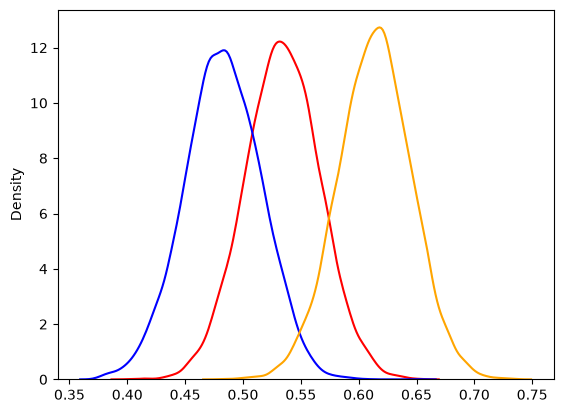

In [20]:
# KDEs of outcomes
sns.kdeplot(outcome_lifestyle, label="lifestyle", color="red")
sns.kdeplot(outcome_met, color="blue")
sns.kdeplot(outcome_rosi, color="orange")

<Axes: ylabel='Proportion'>

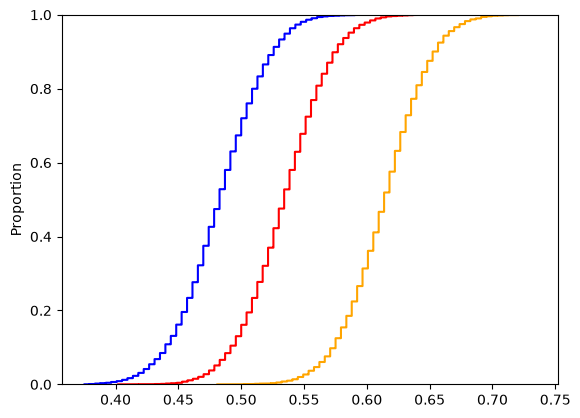

In [21]:
# ECDFs of outcomes
sns.ecdfplot(outcome_lifestyle, label="lifestyle", color="red")
sns.ecdfplot(outcome_met, color="blue")
sns.ecdfplot(outcome_rosi, color="orange")

- Same/Similar distribution and shape across both KDEs and ECDFs
- met is consistently the leftmost plot for both KDE and ECDF
- All three groups' KDEs overlap

<Axes: ylabel='Density'>

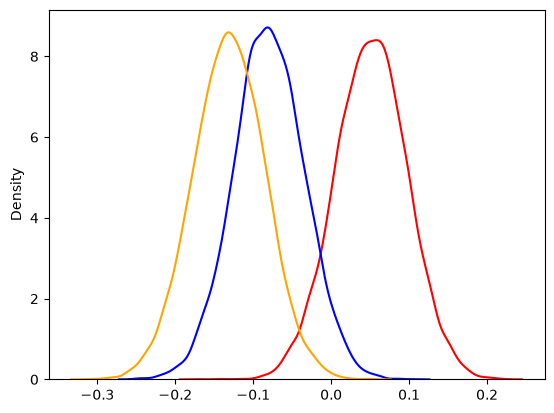

In [22]:
# KDEs of ATEs
sns.kdeplot(life_met_effect, color="red")
sns.kdeplot(life_rosi_effect, color="blue")
sns.kdeplot(met_rosi_effect, color="orange")

<Axes: ylabel='Proportion'>

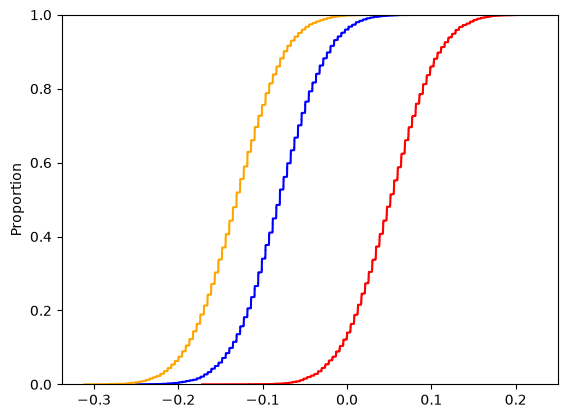

In [23]:
# ECDFs of ATEs
sns.ecdfplot(life_met_effect, color="red")
sns.ecdfplot(life_rosi_effect, color="blue")
sns.ecdfplot(met_rosi_effect, color="orange")

In [25]:
life_met_90 = np.quantile(life_met_effect, [.05, .95])
life_met_95 = np.quantile(life_met_effect, [.025, .975])
life_met_99 = np.quantile(life_met_effect, [.005, .995])

print(f"90% CI for lifestyle vs met treatment: {life_met_90}")
print(f"95% CI for lifestyle vs met treatment: {life_met_95}")
print(f"99% CI for lifestyle vs met treatment: {life_met_99}")

print()

life_rosi_90 = np.quantile(life_rosi_effect, [.05, .95])
life_rosi_95 = np.quantile(life_rosi_effect, [.025, .975])
life_rosi_99 = np.quantile(life_rosi_effect, [.005, .995])

print(f"90% CI for lifestyle vs rosi treatment: {life_rosi_90}")
print(f"95% CI for lifestyle vs rosi treatment: {life_rosi_95}")
print(f"99% CI for lifestyle vs rosi treatment: {life_rosi_99}")

print()

met_rosi_90 = np.quantile(met_rosi_effect, [.05, .95])
met_rosi_95 = np.quantile(met_rosi_effect, [.025, .975])
met_rosi_99 = np.quantile(met_rosi_effect, [.005, .995])

print(f"90% CI for met vs rosi treatment: {met_rosi_90}")
print(f"95% CI for met vs rosi treatment: {met_rosi_95}")
print(f"99% CI for met vs rosi treatment: {met_rosi_99}")

90% CI for lifestyle vs met treatment: [-0.02578839  0.12850169]
95% CI for lifestyle vs met treatment: [-0.03875626  0.14165193]
99% CI for lifestyle vs met treatment: [-0.06450836  0.16767923]

90% CI for lifestyle vs rosi treatment: [-0.15261913 -0.00663952]
95% CI for lifestyle vs rosi treatment: [-0.16943619  0.01034491]
99% CI for lifestyle vs rosi treatment: [-0.19940593  0.03607745]

90% CI for met vs rosi treatment: [-0.20835892 -0.05773642]
95% CI for met vs rosi treatment: [-0.22134453 -0.04071703]
99% CI for met vs rosi treatment: [-0.25133214 -0.0147054 ]


- lifestyle overlaps with both met and rosi, 0 is in the confidence interval
- Largest difference is between met and rosi, 0 is not in the confidence interval

# Report

Using the given diabetes treatment data, we treat a successful outcome as a 1 and a failed outcome as 0. Averaging the outcomes across each treatment, we already get some telling evidence that one treatment is inferior. The Met treatment is the only group where the average is below 0.5. When failures are zeroes and successes are ones, an average less than 0.5 means that there are more failures than successes. A cross-tabulation across all treatment groups supports this, as the Met group has 120 failures compared to 112 successes. To take this analysis further, we move onto bootstrapping.

Each treatment group is separated into their own dataset, and a sample equal to the size of the dataset is made by resampling with replacement. For each sample, the mean is computed, and differences between the treatment means are computed to get the average treatment effects for lifestyle vs Met, lifestyle vs Rosi, and Met vs Rosi. 10,000 samples are made, and the ECDFs and KDEs of their means are plotted. Across the KDEs for the treatment boostraps,the plot for Met is consistently the lowest, the lifestyle plot is in the middle, and the Rosi plot is the greatest. The Met KDE is farthest to the left showing that sample means cluster at lower values, and the lower values are caused by the presence of more zeroes or failures in the sample. Similarly, the Met ECDF is above the other two treatments' ECDFs, meaning that for any given value, a larger proportion of sample means in the Met treatment group will fall below that value. The plots continue to support a conclusion that Met is the least effective treatment, while Rosi is the best.

Next, we look at the KDE and ECDF plots for the average treatment effects of all the combinations of the treatment groups: Lifestyle vs Met, Lifestyle vs Rosi, and Met vs Rosi. As with the KDEs and ECDFs of the bootstrap sample means, the plots of the ATEs are also in the same order across both KDEs and ECDFs. Met vs Rosi is the least, Lifestyle vs Rosi is in the middle, and Lifestyle vs Met is the greatest. Met vs Rosi is an especially interesting comparison, as they were the least and greatest treatments in the sample mean plots respectively. Their ATE KDE clusters most densely at a negative value (around -0.15). In fact, almost all of the KDE is less than 0, and their ECDF is less than 0 as well. Data points were computed with $sample_{met} - sample_{rosi}$, which means that for the KDE to be almost entirely less than 0, this difference must have yielded a negative number almost all of the time, due to a higher sample mean for rosi than met. Similarly, the KDE and ECDF for the lifestyle vs rosi ATE is also mostly below 0, though not to the same degree as Met vs Rosi, suggesting that most rosi sample means were larger than lifestyle means. The KDE and ECDF for lifestyle vs met is mostly above 0, suggesting larger sample means for lifestyle than met.

Lastly, we look at the confidence intervals for the ATEs. Between lifestyle and Met, 0 is present in all three confidence intervals, so we fail to reject the null hypothesis; we cannot say the two treatment groups are different. Between lifestyle and Rosi, the 90% confidence interval does not have 0, but the other two intervals do. There is some evidence for a treatment effect here, but it is weak. Between Met and Rosi is where we see the most significant findings. 0 is not present across all three intervals; they are all negative. This supports the KDE and ECDF of the Met vs Rosi ATE and shows that the sample means for Rosi are always larger than the sample means for Met. Going back to how the sample means are computed, this shows that the Rosi treatment group has many more successes than the Met treatment group.

With all these findings, it is still hard to say with certainty which treatment is best. THe difference between Met and Rosi is significant, but it cannot be said that Rosi is the best treatment because the 2 of the 3 confidence intervals between Rosi and Lifestyle contain zero, suggesting strong evidence for no difference between the groups. The confidence intervals between Lifestyle and Met also contain zero. So if we say that there is no difference between the Lifestyle and Rosi groups (lifestyle = rosi), and there is also no difference between the Lifestyle and Met groups (lifestyle = met), it is difficult to draw a definitive conclusion about Met vs Rosi, and about which treatment is best.